<a href="https://colab.research.google.com/github/Sara200413/AutoPart/blob/main/TP1_Apprentissage_Supervise_Sara_Echffani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(90deg,#1e3a8a,#2563eb);padding:28px;border-radius:12px;color:white">
<h1 style="margin:0;color:white">TP N°1 : Apprentissage supervisé avec Scikit-learn</h1>
<p style="margin:6px 0 0 0;font-size:16px">Module : Technologies IA &nbsp;|&nbsp; ENSA Fès &nbsp;|&nbsp; Ingénierie Logicielle et Intelligence Artificielle (ILIA2)</p>
</div>

| | |
|---|---|
| **Étudiante** | **Sara Echffani N:11** |


---

## Objectifs du TP
- Comprendre et appliquer les étapes d'un apprentissage supervisé.
- Manipuler des modèles de **régression** et de **classification** avec Scikit-learn.
- Savoir **préparer, entraîner, évaluer et interpréter** un modèle.

## Sommaire
1. [Configuration et chargement des fichiers](#config)
2. **Partie 1, Exercice 1** : Régression : prédiction du tarif d'un trajet Uber
3. **Partie 1, Exercice 2** : Classification : survie sur le Titanic
4. **Partie 2** : Mini-projet : prédiction du prix des maisons en Californie (compte rendu)

<a id="config"></a>
## 0. Configuration et chargement des fichiers

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 30)


fichiers = ["uber.csv", "train.csv", "housing.csv"]
manquants = [f for f in fichiers if not os.path.exists(f)]
if manquants:
    try:
        from google.colab import files
        print("Fichiers à charger :", manquants)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Fichiers introuvables : {manquants}")
print("Tous les fichiers sont disponibles :", all(os.path.exists(f) for f in fichiers))

Tous les fichiers sont disponibles : True


<div style="background:#2563eb;padding:16px;border-radius:10px;color:white">
<h1 style="margin:0;color:white">PARTIE 1 : Exercices</h1>
</div>

<div style="background:#0f766e;padding:14px;border-radius:10px;color:white">
<h2 style="margin:0;color:white">Exercice 1 : Régression : prédiction du tarif d'un trajet Uber</h2>
</div>

**Jeu de données :** Uber Fare Prediction Dataset (Kaggle).
**Objectif :** prédire le prix d'un trajet (`fare_amount`) à partir de la distance, de l'heure, du jour de la semaine, etc.

### Étape 1 : Chargement et exploration du jeu de données

In [ ]:
data = pd.read_csv('uber.csv')
print("Dimensions :", data.shape)
data.head()

Dimensions : (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [ ]:
print("Valeurs manquantes par colonne :")
print(data.isnull().sum())
data.describe().T

Valeurs manquantes par colonne :
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,2.771250e+07,1.601382e+07,1.000000,1.382535e+07,2.774550e+07,4.155530e+07,5.542357e+07
fare_amount,200000.0,1.135996e+01,9.901776e+00,-52.000000,6.000000e+00,8.500000e+00,1.250000e+01,4.990000e+02
pickup_longitude,200000.0,-7.252764e+01,1.143779e+01,-1340.648410,-7.399206e+01,-7.398182e+01,-7.396715e+01,5.741846e+01
pickup_latitude,200000.0,3.993589e+01,7.720539e+00,-74.015515,4.073480e+01,4.075259e+01,4.076716e+01,1.644421e+03
dropoff_longitude,199999.0,-7.252529e+01,1.311741e+01,-3356.666300,-7.399141e+01,-7.398009e+01,-7.396366e+01,1.153573e+03
dropoff_latitude,199999.0,3.992389e+01,6.794829e+00,-881.985513,4.073382e+01,4.075304e+01,4.076800e+01,8.726976e+02
passenger_count,200000.0,1.684535e+00,1.385997e+00,0.000000,1.000000e+00,1.000000e+00,2.000000e+00,2.080000e+02


**Observations :**
- Le fichier contient **200 000 trajets**, et la variable cible est `fare_amount`.
- Seules les colonnes `dropoff_longitude` et `dropoff_latitude` ont une valeur manquante (1 ligne).
- Le jeu de données ne contient **pas de colonne `distance`** : il faut la calculer à partir des coordonnées GPS (formule de Haversine).
- Il y a des **valeurs aberrantes** : tarifs négatifs ou très élevés, coordonnées à 0, nombre de passagers égal à 0 ou supérieur à 6.

### Étape 2 : Nettoyage et préparation

In [ ]:
data = data.dropna()

# Tarifs positifs
data = data[data['fare_amount'] > 0]

# Nombre de passagers réaliste
data = data[(data['passenger_count'] >= 1) & (data['passenger_count'] <= 6)]

# Coordonnées dans la zone de New York
data = data[
    data['pickup_longitude'].between(-75, -72) & data['dropoff_longitude'].between(-75, -72) &
    data['pickup_latitude'].between(40, 42) & data['dropoff_latitude'].between(40, 42)
]

# Variables dérivées : date
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek
data['year'] = data['pickup_datetime'].dt.year

# Distance  en km
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

data['distance'] = haversine(data['pickup_latitude'], data['pickup_longitude'],
                             data['dropoff_latitude'], data['dropoff_longitude'])

# On retire les trajets de distance nulle ou irréaliste, et les tarifs extrêmes
data = data[(data['distance'] > 0.1) & (data['distance'] < 100)]
data = data[data['fare_amount'] < 150]

print("Taille après nettoyage :", data.shape)
data[['fare_amount', 'distance', 'hour', 'day_of_week', 'year']].describe().T

Taille après nettoyage : (191882, 13)


,count,mean,std,min,25%,50%,75%,max
fare_amount,191882.0,11.311324,9.403698,0.010000,6.000000,8.50000,12.500000,148.330000
distance,191882.0,3.380379,3.717322,0.100227,1.294804,2.19304,3.957018,99.162509
hour,191882.0,13.494059,6.514920,0.000000,9.000000,14.00000,19.000000,23.000000
day_of_week,191882.0,3.049530,1.946490,0.000000,1.000000,3.00000,5.000000,6.000000
year,191882.0,2011.747699,1.862649,2009.000000,2010.000000,2012.00000,2013.000000,2015.000000


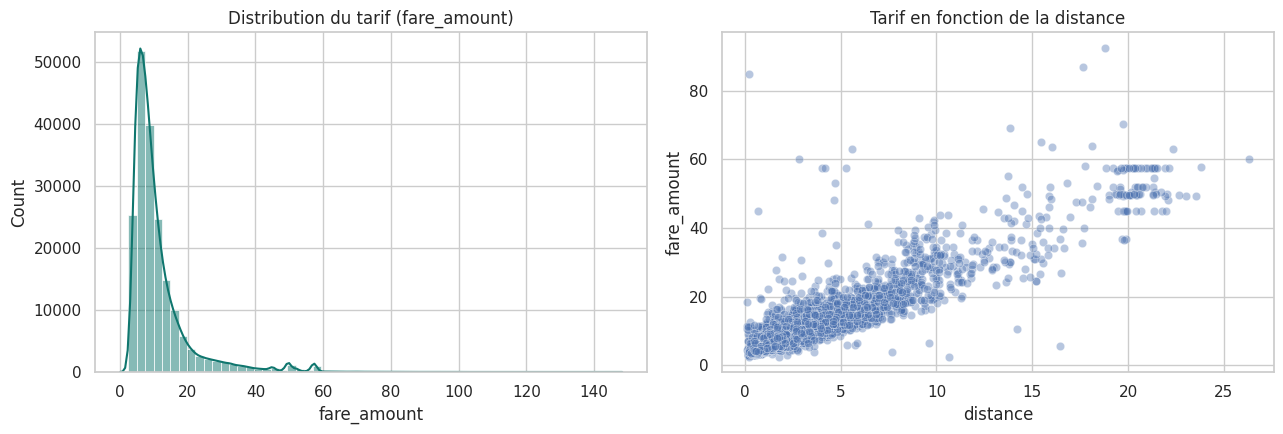

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data['fare_amount'], bins=60, kde=True, ax=ax[0], color="#0f766e")
ax[0].set_title("Distribution du tarif (fare_amount)")
sns.scatterplot(x='distance', y='fare_amount', data=data.sample(5000, random_state=42), alpha=.4, ax=ax[1])
ax[1].set_title("Tarif en fonction de la distance")
plt.tight_layout(); plt.show()

### Étape 3 : Séparation des données

In [ ]:
from sklearn.model_selection import train_test_split

X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (153505, 3) | Test : (38377, 3)


### Étape 4 : Entraînement du modèle (Régression linéaire)

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print("Coefficients :", dict(zip(X.columns, lr.coef_.round(3))))
print("Intercept    :", round(lr.intercept_, 3))

Coefficients : {'distance': np.float64(2.2), 'hour': np.float64(0.01), 'day_of_week': np.float64(-0.042)}
Intercept    : 3.874


### Étape 5 : Évaluation du modèle

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print('MAE  =', round(mae, 3), '$')
print('RMSE =', round(rmse, 3), '$')
print('R²   =', round(r2, 3))

MAE  = 2.323 $
RMSE = 4.678 $
R²   = 0.756


**Interprétation :** la `distance` est le facteur dominant du tarif (environ 2 à 3 $ par km). Les variables `hour` et `day_of_week` ont une relation **non linéaire** avec le prix, donc une régression linéaire n'est pas idéale ici.

### Étape 6 : Amélioration avec Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

def scores(nom, y_true, y_hat):
    return {"Modèle": nom,
            "MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
            "R²": r2_score(y_true, y_hat)}

res_uber = pd.DataFrame([scores("Régression linéaire", y_test, y_pred),
                         scores("Random Forest", y_test, y_pred_rf)]).set_index("Modèle").round(3)
res_uber

,MAE,RMSE,R²
Modèle,,,
Régression linéaire,2.323,4.678,0.756
Random Forest,2.418,4.327,0.791


### Étape 7 : Visualisation des résultats

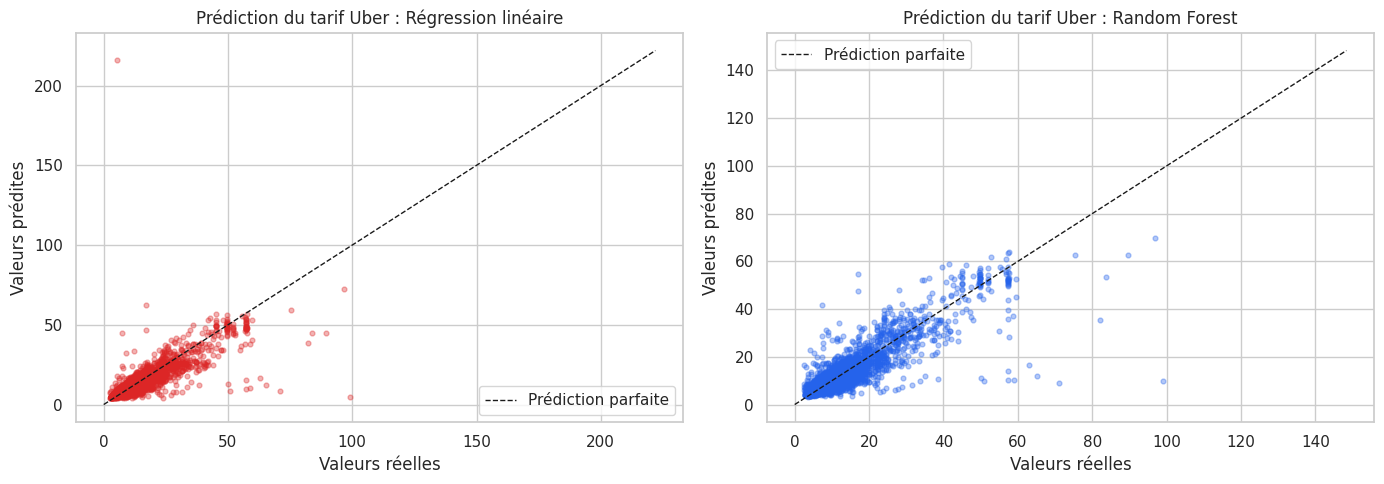

In [ ]:
idx = np.random.RandomState(42).choice(len(y_test), 5000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for a, pred, titre, c in [(ax[0], y_pred, "Régression linéaire", "#dc2626"),
                          (ax[1], y_pred_rf, "Random Forest", "#2563eb")]:
    a.scatter(y_test.values[idx], pred[idx], alpha=0.35, color=c, s=12)
    m = max(y_test.max(), pred.max())
    a.plot([0, m], [0, m], 'k--', lw=1, label="Prédiction parfaite")
    a.set_xlabel('Valeurs réelles'); a.set_ylabel('Valeurs prédites')
    a.set_title(f'Prédiction du tarif Uber : {titre}'); a.legend()
plt.tight_layout(); plt.show()

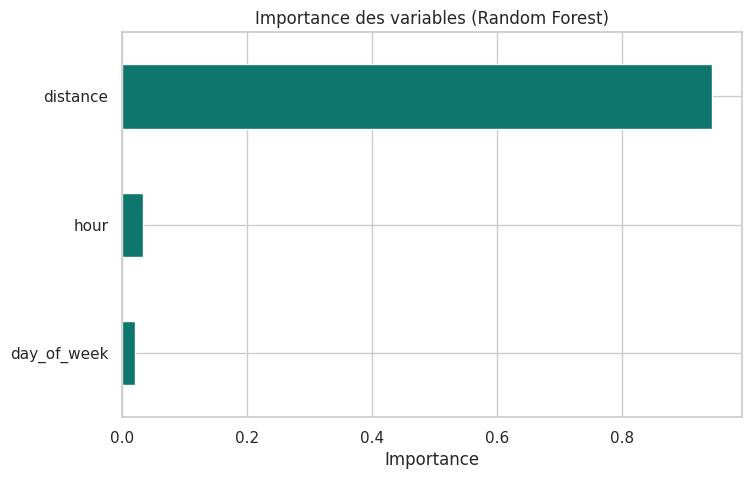

In [ ]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', color="#0f766e", title="Importance des variables (Random Forest)")
plt.xlabel("Importance"); plt.show()

### Amélioration supplémentaire : ajout de l'année
Les tarifs Uber/taxi de New York ont augmenté au fil des années (hausse tarifaire de 2012). On ajoute donc `year` comme variable pour voir l'effet sur le modèle.

In [ ]:
X2 = data[['distance', 'hour', 'day_of_week', 'year', 'passenger_count']]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

rf2 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf2.fit(X2_train, y2_train)
res_uber.loc["Random Forest + year + passagers"] = [
    mean_absolute_error(y2_test, rf2.predict(X2_test)),
    np.sqrt(mean_squared_error(y2_test, rf2.predict(X2_test))),
    r2_score(y2_test, rf2.predict(X2_test))]
res_uber.round(3)

,MAE,RMSE,R²
Modèle,,,
Régression linéaire,2.323,4.678,0.756
Random Forest,2.418,4.327,0.791
Random Forest + year + passagers,2.148,3.971,0.824


### Conclusion de l'Exercice 1
- La **régression linéaire** donne déjà un bon résultat de base (R² ≈ 0,76) car le tarif dépend surtout de la **distance** (≈ 2,2 $/km).
- Le **Random Forest** réduit nettement le **RMSE** (≈ 4,33 $ contre ≈ 4,68 $) et améliore le R² (≈ 0,79) : il capte mieux les erreurs importantes (trajets longs, effets non linéaires). Son **MAE** est en revanche légèrement plus élevé (≈ 2,42 $ contre ≈ 2,32 $), donc le choix dépend de la métrique : le RMSE pénalise davantage les grosses erreurs.
- L'ajout de **l'année** et du **nombre de passagers** améliore encore le modèle (**RMSE ≈ 3,97 $, R² ≈ 0,82**), ce qui confirme l'effet de l'inflation tarifaire au fil du temps.
- Limite : les trajets de même distance peuvent avoir des prix différents (trafic, péages, aéroport) : ces informations manquent dans les variables.

*(Valeurs approximatives : de légers écarts sont possibles selon la version de scikit-learn.)*

<div style="background:#7c3aed;padding:14px;border-radius:10px;color:white">
<h2 style="margin:0;color:white">Exercice 2 : Classification : prédire la survie sur le Titanic</h2>
</div>

**Jeu de données :** Titanic : Machine Learning from Disaster (Kaggle). On utilise le fichier `train.csv` (891 passagers) car c'est le seul qui contient la colonne cible `Survived`.
**Objectif :** prédire si un passager a survécu (1) ou non (0) au naufrage.

### Étape 1 : Chargement et exploration

In [ ]:
data = pd.read_csv('train.csv')
print("Dimensions :", data.shape)
data.head()

Dimensions : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
data.info()
print("\nValeurs manquantes :")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Valeurs manquantes :
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked     

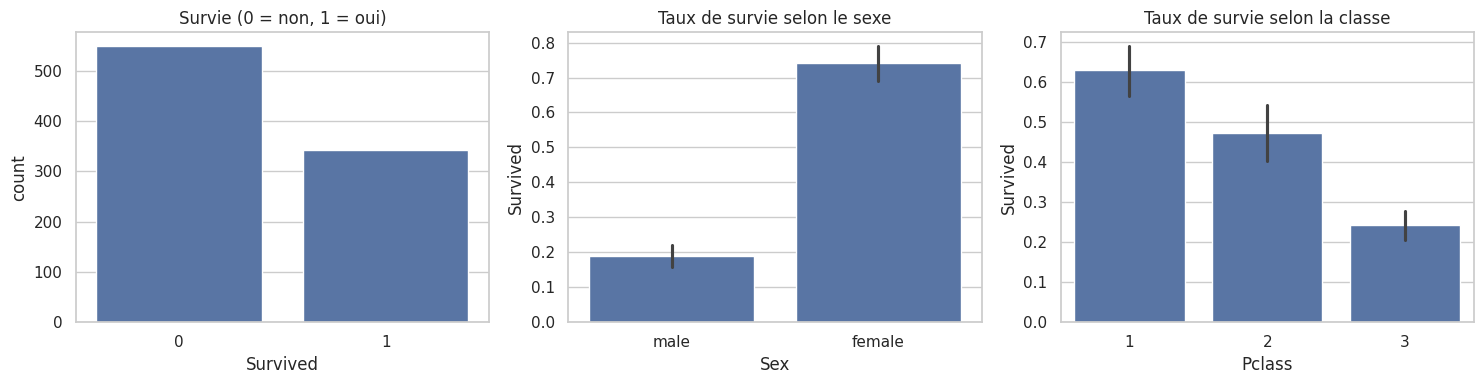

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='Survived', data=data, ax=ax[0]); ax[0].set_title("Survie (0 = non, 1 = oui)")
sns.barplot(x='Sex', y='Survived', data=data, ax=ax[1]); ax[1].set_title("Taux de survie selon le sexe")
sns.barplot(x='Pclass', y='Survived', data=data, ax=ax[2]); ax[2].set_title("Taux de survie selon la classe")
plt.tight_layout(); plt.show()

**Observations :** `Age` (177 manquants), `Cabin` (687 manquants) et `Embarked` (2 manquants) contiennent des valeurs manquantes. Le **sexe** et la **classe** semblent très liés à la survie (les femmes et la 1ère classe survivent beaucoup plus).

### Étape 2 : Nettoyage et traitement

In [ ]:
data = data[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']].copy()
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
print("Valeurs manquantes restantes :", data.isnull().sum().sum())
data.head()

Valeurs manquantes restantes : 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### Étape 3 : Encodage des variables catégorielles

In [ ]:
from sklearn.preprocessing import LabelEncoder

le_sex, le_emb = LabelEncoder(), LabelEncoder()
data['Sex'] = le_sex.fit_transform(data['Sex'])
data['Embarked'] = le_emb.fit_transform(data['Embarked'])
print("Sex      :", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Embarked :", dict(zip(le_emb.classes_, le_emb.transform(le_emb.classes_))))
data.head()

Sex      : {'female': np.int64(0), 'male': np.int64(1)}
Embarked : {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


### Étape 4 : Séparation des données

In [ ]:
X = data.drop('Survived', axis=1)
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (712, 7) | Test : (179, 7)


### Étape 5 : Entraînement des modèles

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
print("Modèles entraînés ✔")

Modèles entraînés ✔


### Étape 6 : Évaluation des modèles

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print('Accuracy (Logistic)     :', round(accuracy_score(y_test, y_pred_log), 4))
print('Accuracy (Random Forest):', round(accuracy_score(y_test, y_pred_rf), 4))
print("\n--- Rapport de classification : Random Forest ---")
print(classification_report(y_test, y_pred_rf, target_names=["Décédé (0)", "Survivant (1)"]))
print("--- Rapport de classification : Régression logistique ---")
print(classification_report(y_test, y_pred_log, target_names=["Décédé (0)", "Survivant (1)"]))

Accuracy (Logistic)     : 0.8101
Accuracy (Random Forest): 0.8212

--- Rapport de classification : Random Forest ---
               precision    recall  f1-score   support

   Décédé (0)       0.83      0.88      0.85       105
Survivant (1)       0.81      0.74      0.77        74

     accuracy                           0.82       179
    macro avg       0.82      0.81      0.81       179
 weighted avg       0.82      0.82      0.82       179

--- Rapport de classification : Régression logistique ---
               precision    recall  f1-score   support

   Décédé (0)       0.83      0.86      0.84       105
Survivant (1)       0.79      0.74      0.76        74

     accuracy                           0.81       179
    macro avg       0.81      0.80      0.80       179
 weighted avg       0.81      0.81      0.81       179



### Étape 7 : Matrice de confusion

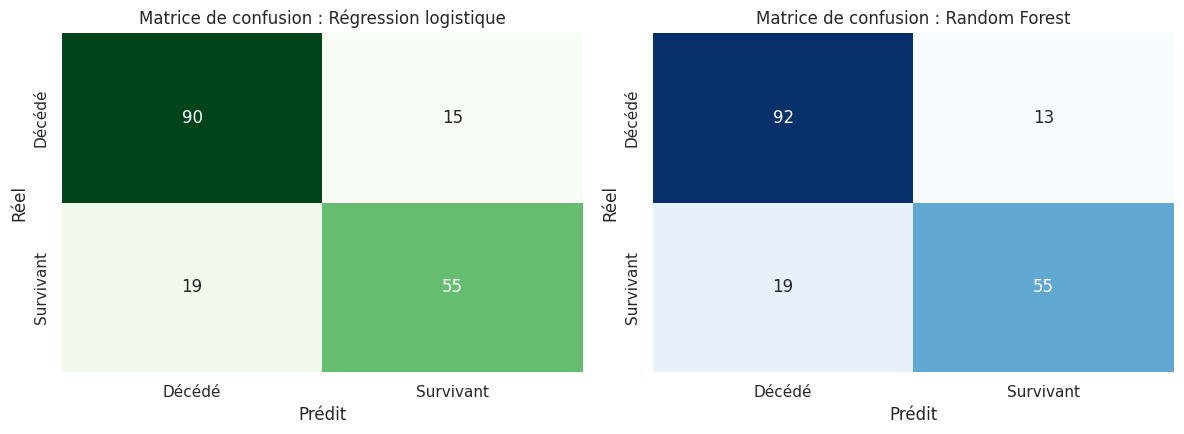

In [ ]:
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, pred, titre, cmap in [(ax[0], y_pred_log, "Régression logistique", "Greens"),
                             (ax[1], y_pred_rf, "Random Forest", "Blues")]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=a, cbar=False,
                xticklabels=["Décédé", "Survivant"], yticklabels=["Décédé", "Survivant"])
    a.set_title(f'Matrice de confusion : {titre}'); a.set_xlabel('Prédit'); a.set_ylabel('Réel')
plt.tight_layout(); plt.show()

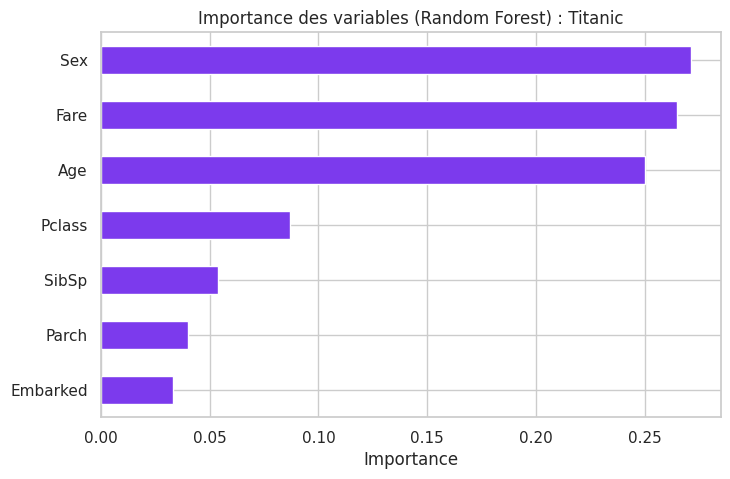

In [ ]:
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', color="#7c3aed", title="Importance des variables (Random Forest) : Titanic")
plt.xlabel("Importance"); plt.show()

### Conclusion de l'Exercice 2
- Les deux modèles obtiennent des performances proches : **Régression logistique ≈ 81 %** et **Random Forest ≈ 82 %** d'accuracy sur le jeu de test (179 passagers).
- Le Random Forest est un peu meilleur, mais l'écart est faible sur un si petit échantillon : il n'est pas forcément significatif.
- Dans les deux cas, le modèle repère mieux les **décédés** (recall ≈ 0,86 à 0,88) que les **survivants** (recall ≈ 0,74) : la classe « survivant » est moins nombreuse.
- Variables les plus importantes pour le Random Forest : **Sex, Fare et Age**, puis `Pclass`. Cela reflète la règle historique « les femmes et les enfants d'abord » et l'avantage des classes supérieures.

<div style="background:#b45309;padding:16px;border-radius:10px;color:white">
<h1 style="margin:0;color:white">PARTIE 2 : Mini-projet et compte rendu</h1>
<p style="margin:6px 0 0 0">Prédiction du prix médian des maisons en Californie (California Housing)</p>
</div>

**Démarche :** application du workflow complet d'apprentissage supervisé :
exploration, prétraitement, séparation, comparaison rigoureuse de modèles (validation croisée), évaluation, interprétation et conclusion critique.

**Problème :** prédire `median_house_value` (régression) à partir de la localisation, de l'âge des maisons, du revenu médian, de la population, etc.

## 1. Chargement et exploration

In [ ]:
housing = pd.read_csv('housing.csv')
print("Dimensions :", housing.shape)
housing.head()

Dimensions : (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
housing.info()
print("\nValeurs manquantes :")
print(housing.isnull().sum()[lambda s: s > 0])
print("\nCatégories ocean_proximity :")
print(housing['ocean_proximity'].value_counts())
housing.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Valeurs manquantes :
total_bedrooms    207
dtype: int64

Catégories ocean_proximity :
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


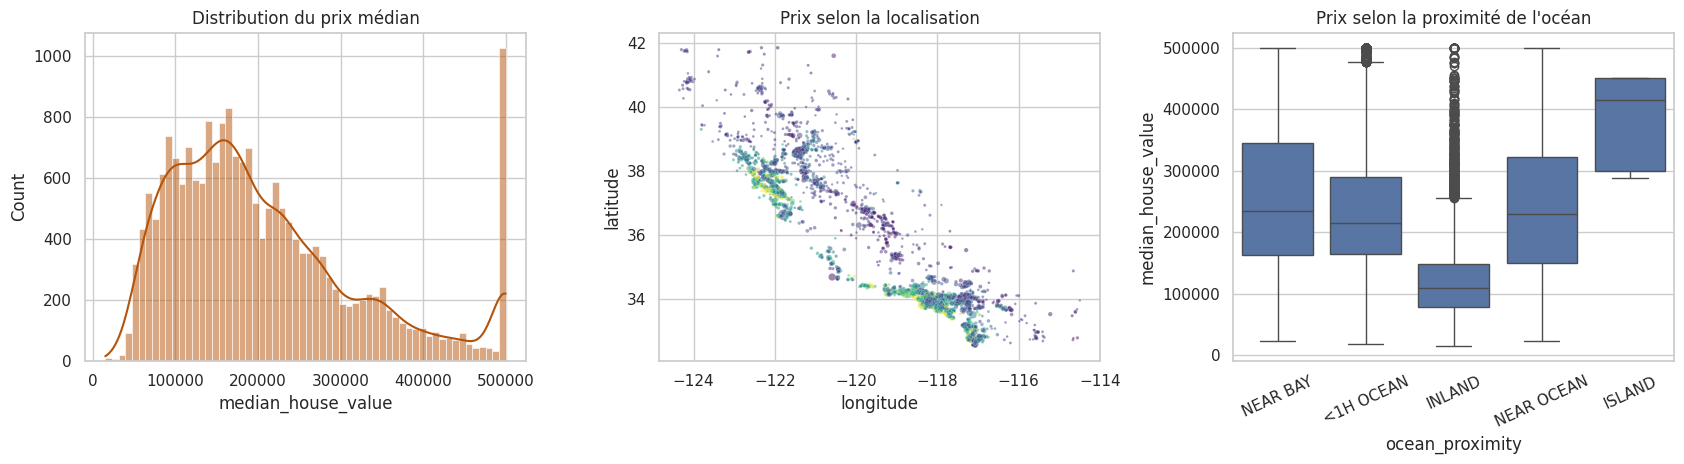

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.histplot(housing['median_house_value'], bins=60, kde=True, ax=ax[0], color="#b45309")
ax[0].set_title("Distribution du prix médian")
sns.scatterplot(x='longitude', y='latitude', hue='median_house_value', palette='viridis',
                size='population', sizes=(3, 60), alpha=.5, data=housing.sample(6000, random_state=1), ax=ax[1], legend=False)
ax[1].set_title("Prix selon la localisation")
sns.boxplot(x='ocean_proximity', y='median_house_value', data=housing, ax=ax[2])
ax[2].set_title("Prix selon la proximité de l'océan"); ax[2].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

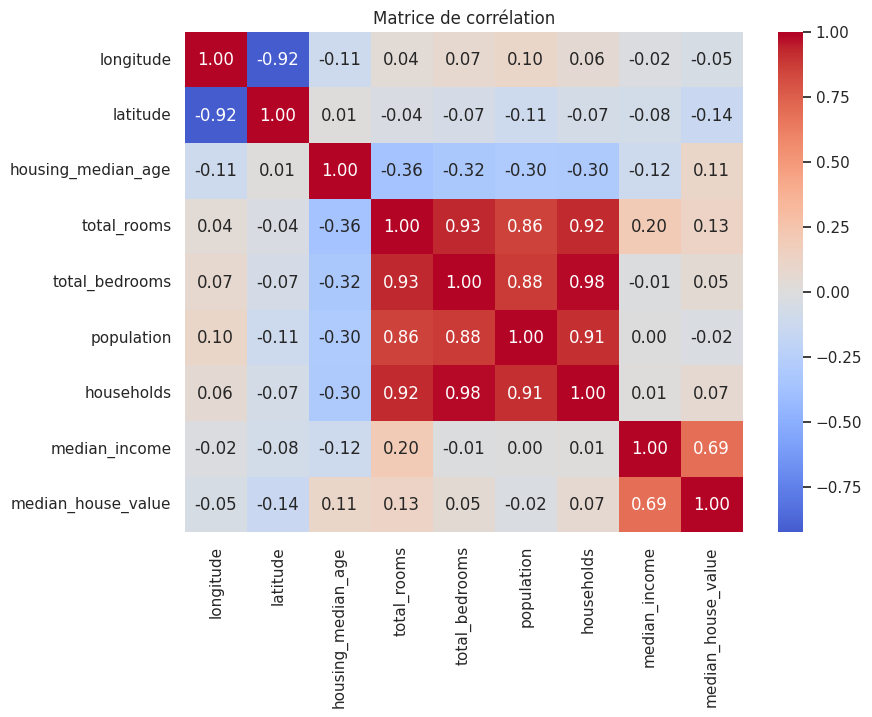

In [ ]:
plt.figure(figsize=(9, 6.5))
sns.heatmap(housing.drop(columns='ocean_proximity').corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation"); plt.show()

**Observations :**
- `total_bedrooms` a **207 valeurs manquantes** : on les imputera avec la médiane.
- Le prix est **plafonné à 500 001 $** (pic à droite de la distribution) : c'est une limite du jeu de données qui va limiter la précision du modèle sur les maisons chères.
- `median_income` est de très loin la variable la plus corrélée au prix.
- `ocean_proximity` est une variable **catégorielle** : encodage One-Hot nécessaire.
- Les variables `total_rooms`, `total_bedrooms`, `population`, `households` sont fortement corrélées entre elles et très asymétriques.

## 2. Prétraitement

Choix de prétraitement (justifiés) :
1. **Séparation train/test d'abord** pour éviter toute fuite d'information (*data leakage*).
2. **Variables dérivées** plus informatives que les totaux bruts : `rooms_per_household`, `bedrooms_per_room`, `population_per_household`.
3. **Imputation** par la médiane (robuste aux valeurs extrêmes), apprise sur le train uniquement.
4. **Standardisation** des variables numériques (utile pour les modèles linéaires).
5. **One-Hot encoding** de `ocean_proximity`.
Tout est regroupé dans un `Pipeline` / `ColumnTransformer` pour garantir que le même traitement est appliqué à chaque fold de validation croisée.

In [ ]:
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = housing.copy()
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

X = df.drop('median_house_value', axis=1)
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = ['ocean_proximity']

preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Variables numériques :", num_cols)

Train : (16512, 12) | Test : (4128, 12)
Variables numériques : ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']


## 3. Comparaison rigoureuse des modèles (validation croisée 5 folds)

On compare **5 modèles** de complexité croissante, tous avec le même prétraitement et le même découpage `KFold(5)` sur le **jeu d'entraînement uniquement**. Le jeu de test n'est utilisé qu'à la fin, une seule fois.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

modeles = {
    "Régression linéaire": LinearRegression(),
    "Ridge (α=1)": Ridge(alpha=1.0),
    "Arbre de décision": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting (Hist)": HistGradientBoostingRegressor(random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
lignes = []
for nom, m in modeles.items():
    pipe = Pipeline([('prep', preprocess), ('model', m)])
    cv = cross_validate(pipe, X_train, y_train, cv=kf, n_jobs=-1,
                        scoring=['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error'])
    lignes.append({"Modèle": nom,
                   "R² (CV)": cv['test_r2'].mean(), "R² écart-type": cv['test_r2'].std(),
                   "RMSE (CV)": -cv['test_neg_root_mean_squared_error'].mean(),
                   "MAE (CV)": -cv['test_neg_mean_absolute_error'].mean()})

res_cv = pd.DataFrame(lignes).set_index("Modèle").sort_values("RMSE (CV)")
res_cv.round(3).style.background_gradient(cmap="Greens_r", subset=["RMSE (CV)", "MAE (CV)"]) \
      .background_gradient(cmap="Greens", subset=["R² (CV)"])

,R² (CV),R² écart-type,RMSE (CV),MAE (CV)
Modèle,,,,
Gradient Boosting (Hist),0.835000,0.005000,46910.062000,31201.648000
Random Forest,0.811000,0.005000,50299.453000,32911.449000
Arbre de décision,0.715000,0.006000,61680.085000,40740.805000
Ridge (α=1),0.655000,0.014000,67849.203000,48876.806000
Régression linéaire,0.655000,0.014000,67858.779000,48879.909000


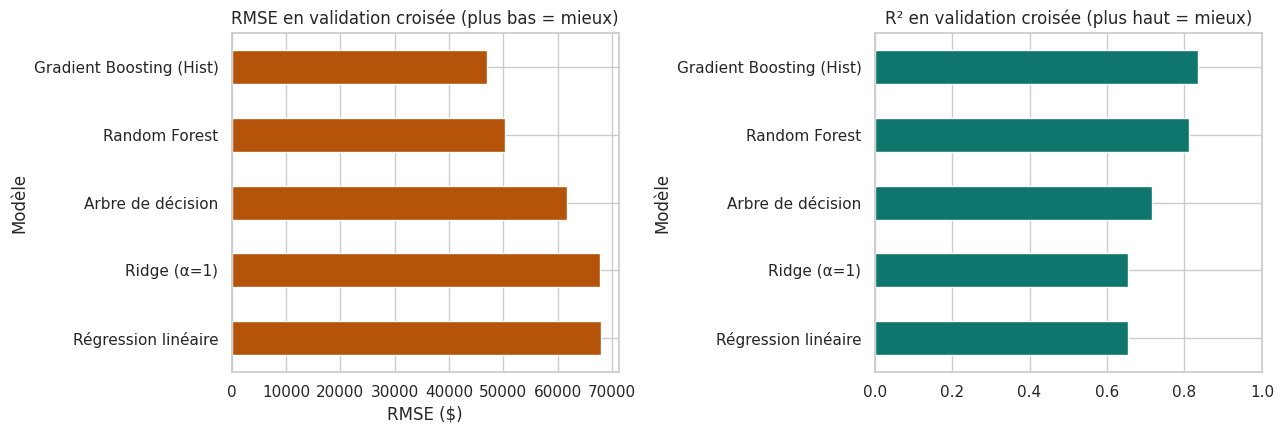

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
res_cv["RMSE (CV)"].sort_values(ascending=False).plot(kind='barh', ax=ax[0], color="#b45309")
ax[0].set_title("RMSE en validation croisée (plus bas = mieux)"); ax[0].set_xlabel("RMSE ($)")
res_cv["R² (CV)"].sort_values().plot(kind='barh', ax=ax[1], color="#0f766e")
ax[1].set_title("R² en validation croisée (plus haut = mieux)"); ax[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

## 4. Optimisation des hyperparamètres du meilleur modèle

In [ ]:
pipe_gb = Pipeline([('prep', preprocess), ('model', HistGradientBoostingRegressor(random_state=42))])
grille = {
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__max_iter': [200, 400],
    'model__max_depth': [None, 8],
}
gs = GridSearchCV(pipe_gb, grille, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
gs.fit(X_train, y_train)
print("Meilleurs paramètres :", gs.best_params_)
print("RMSE CV (3 folds)    :", round(-gs.best_score_, 1), "$")

Meilleurs paramètres : {'model__learning_rate': 0.05, 'model__max_depth': None, 'model__max_iter': 400}
RMSE CV (3 folds)    : 46156.8 $


## 5. Évaluation finale sur le jeu de test

In [ ]:
# Réentraînement de chaque modèle sur tout le train, évaluation unique sur le test
finaux = {nom: Pipeline([('prep', preprocess), ('model', m)]).fit(X_train, y_train)
          for nom, m in modeles.items()}
finaux["Gradient Boosting (optimisé)"] = gs.best_estimator_

lignes = []
for nom, p in finaux.items():
    pred = p.predict(X_test)
    lignes.append({"Modèle": nom,
                   "MAE": mean_absolute_error(y_test, pred),
                   "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                   "R²": r2_score(y_test, pred)})
res_test = pd.DataFrame(lignes).set_index("Modèle").sort_values("RMSE")
res_test.round(3)

,MAE,RMSE,R²
Modèle,,,
Gradient Boosting (optimisé),29490.186,44916.627,0.846
Gradient Boosting (Hist),30474.219,46241.584,0.837
Random Forest,31926.270,49833.732,0.810
Arbre de décision,40302.954,62017.661,0.706
Régression linéaire,49645.492,69127.038,0.635
Ridge (α=1),49652.143,69134.965,0.635


## 6. Interprétation des résultats

Meilleur modèle sur le test : Gradient Boosting (optimisé)


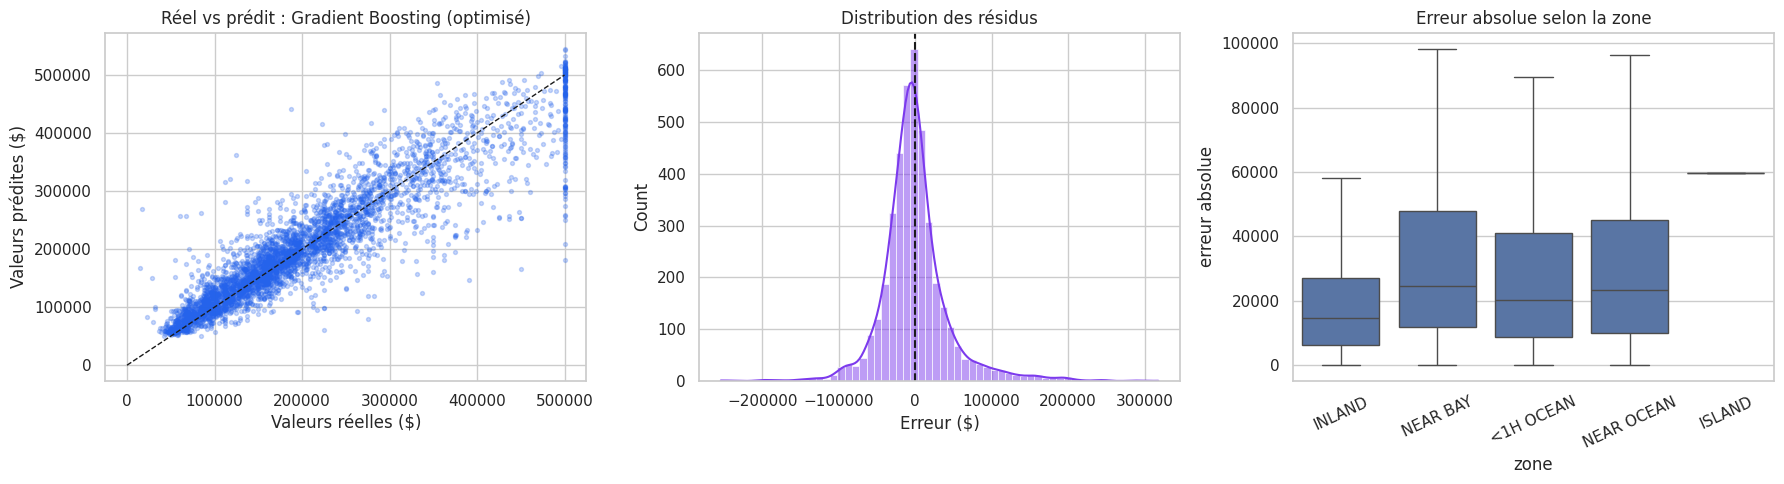

In [ ]:
meilleur_nom = res_test.index[0]
meilleur = finaux[meilleur_nom]
pred = meilleur.predict(X_test)
print("Meilleur modèle sur le test :", meilleur_nom)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
# (a) réel vs prédit
ax[0].scatter(y_test, pred, alpha=.25, s=8, color="#2563eb")
ax[0].plot([0, 5e5], [0, 5e5], 'k--', lw=1)
ax[0].set_xlabel("Valeurs réelles ($)"); ax[0].set_ylabel("Valeurs prédites ($)")
ax[0].set_title(f"Réel vs prédit : {meilleur_nom}")
# (b) résidus
res = y_test - pred
sns.histplot(res, bins=60, kde=True, ax=ax[1], color="#7c3aed")
ax[1].axvline(0, color='k', ls='--'); ax[1].set_title("Distribution des résidus"); ax[1].set_xlabel("Erreur ($)")
# (c) erreur selon la zone
err = pd.DataFrame({"zone": X_test['ocean_proximity'].values, "erreur absolue": res.abs().values})
sns.boxplot(x='zone', y='erreur absolue', data=err, ax=ax[2], showfliers=False)
ax[2].set_title("Erreur absolue selon la zone"); ax[2].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

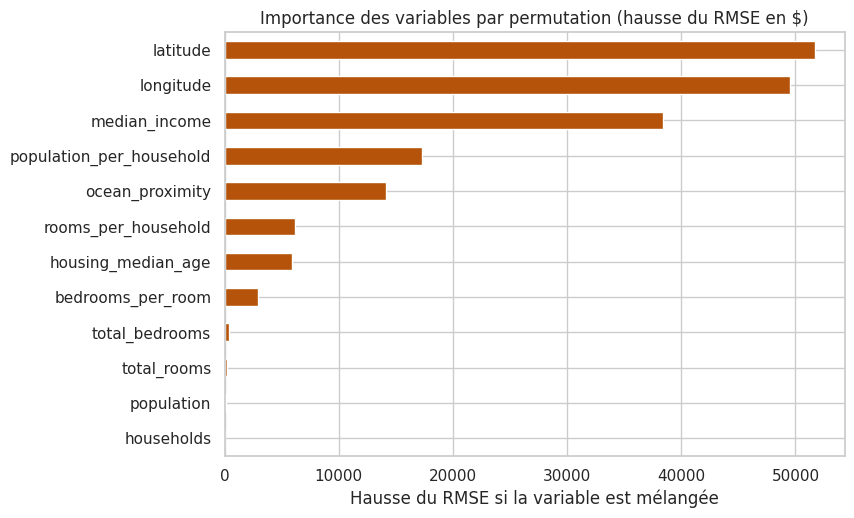

In [ ]:
# Importance des variables par permutation (modèle retenu, sur le test)
from sklearn.inspection import permutation_importance

pi = permutation_importance(meilleur, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1,
                            scoring='neg_root_mean_squared_error')
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind='barh', color="#b45309", figsize=(8, 5.5),
         title="Importance des variables par permutation (hausse du RMSE en $)")
plt.xlabel("Hausse du RMSE si la variable est mélangée"); plt.show()

In [ ]:
# Limite du plafonnement à 500 001 $
plafond = y_test >= 500000
print(f"Part des maisons plafonnées dans le test : {plafond.mean()*100:.1f} %")
print(f"MAE sur maisons plafonnées     : {mean_absolute_error(y_test[plafond], pred[plafond]):,.0f} $")
print(f"MAE sur maisons non plafonnées : {mean_absolute_error(y_test[~plafond], pred[~plafond]):,.0f} $")

Part des maisons plafonnées dans le test : 4.5 %
MAE sur maisons plafonnées     : 63,275 $
MAE sur maisons non plafonnées : 27,914 $


## 7. Conclusion critique : quel modèle retenir, et pourquoi ?

### Tableau de synthèse

| Modèle | RMSE ($) | MAE ($) | R² |
|---|---|---|---|
| **Gradient Boosting (optimisé)** | **≈ 44 700** | **≈ 29 400** | **≈ 0,85** |
| Gradient Boosting (par défaut) | ≈ 46 300 | ≈ 30 600 | ≈ 0,84 |
| Random Forest | ≈ 49 800 | ≈ 31 900 | ≈ 0,81 |
| Arbre de décision | ≈ 62 000 | ≈ 40 300 | ≈ 0,71 |
| Régression linéaire / Ridge | ≈ 69 100 | ≈ 49 600 | ≈ 0,64 |

*(Compare avec le tableau calculé plus haut : de légers écarts sont possibles selon la version de scikit-learn.)*

### Modèle retenu : Gradient Boosting (HistGradientBoostingRegressor) optimisé

**Pourquoi ?**
1. **Meilleur à tous les niveaux** : il est premier en validation croisée **et** sur le jeu de test. Le classement est le même dans les deux évaluations, donc le résultat est **stable** et non dû au hasard du découpage.
2. **Pas de surapprentissage visible** : les scores en validation croisée et sur le test sont très proches.
3. **Gain réel** par rapport à la régression linéaire : l'erreur moyenne (MAE) passe de ≈ 49 600 $ à ≈ 29 400 $ (≈ −40 %). Les relations sont donc **non linéaires** (effet de la localisation, du revenu).
4. **Rapide à entraîner** et gère nativement les valeurs manquantes, ce qui est pratique en production.

**Interprétation :**
- D'après l'importance par permutation, les variables dominantes sont **`median_income`**, puis **`longitude` et `latitude`** (la localisation), puis `population_per_household`. Les variables dérivées créées au prétraitement se montrent plus utiles que les totaux bruts (`total_rooms`, `population`…), ce qui justifie le feature engineering.
- La régression linéaire et Ridge donnent des résultats **quasi identiques** : la régularisation n'apporte rien ici, le problème vient du **manque de flexibilité** du modèle et non de la variance.

**Limites et regard critique :**
- Le prix est **plafonné à 500 001 $** : les maisons plafonnées (≈ 4,5 % du test) sont mal prédites (MAE ≈ 62 000 $ contre ≈ 28 000 $ pour les autres). Le modèle sous-estime les maisons très chères.
- Une erreur moyenne de ≈ 29 000 $ reste importante pour une maison à ≈ 200 000 $ : le modèle est utile pour une **estimation globale**, pas pour une évaluation précise d'un bien.
- Les données datent des années 1990 et sont agrégées par quartier (pas par maison) : la généralisation à des données actuelles ou à d'autres régions n'est pas garantie.
- **Pistes d'amélioration :** traiter à part les valeurs plafonnées, ajouter des variables géographiques (distance aux grandes villes), tester XGBoost/LightGBM, élargir la recherche d'hyperparamètres.

---
<p style="text-align:center;color:gray">TP N°1 : Technologies IA : ENSA Fès : ILIA2 : réalisé par <b>Sara Echffani</b></p>